<a href="https://colab.research.google.com/github/JuanCg42/Deteccion_de_Huecos_en_Carreteras_CNN/blob/main/Entrenamiento/Detecci%C3%B3n_de_Huecos_en_Carreteras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive
from PIL import Image #Se utiliza PIL para poder poder obtener imagenes y agregarlas al informe
import pandas as pd # Se Utiliza para poder general las tablas y agregarlas al informe

drive.mount('/content/drive')

!unzip -q "/content/drive/MyDrive/huecos/huecos.zip" -d "/content/huecos"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/huecos/huecos/Crack/1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A}
A


In [7]:
#Se revisan las carpetas que hay dentro de la carpeta principal, para que se puedan identificar todos los tipo que contienen este DataSet.
ruta_dataset = "/content/huecos/huecos"
print("Clases:", os.listdir(ruta_dataset))

Clases: ['Crack', 'Surface Erosion', 'Normal', 'Pothole']


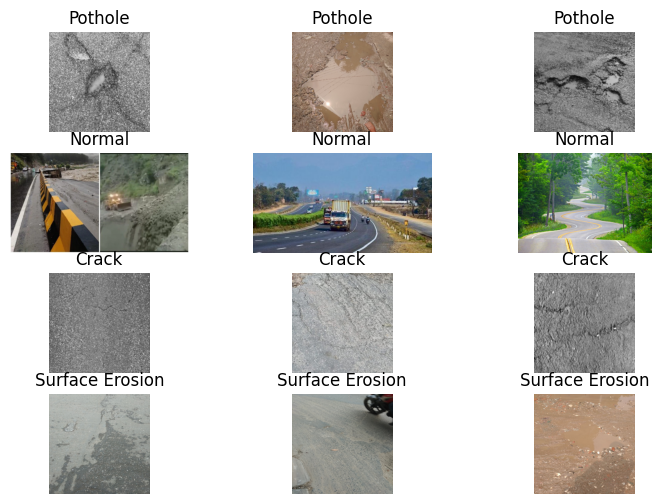

In [17]:
clases = ["Pothole", "Normal", "Crack", "Surface Erosion"]

plt.figure(figsize=(12,6))
for i, clase in enumerate(clases):
    carpeta = ruta_dataset + "/" + clase
    archivos = os.listdir(carpeta)
    for j in range(3):
        imagen = Image.open(carpeta + "/" + archivos[j])
        plt.subplot(4, 4, i*4 + j + 1)
        plt.imshow(imagen)
        plt.title(clase)
        plt.axis("off")
plt.show()

In [19]:
train_ds, test_ds = tf.keras.utils.image_dataset_from_directory(
    ruta_dataset,
    validation_split=0.15,
    subset="both",
    seed=42,
    image_size=(224, 224), #Las redimensionamos debido a que si se reducen se puede hacer un entrenamiento más rapido
    batch_size=2000)

class_names = train_ds.class_names
print("Clases:", class_names)

X_train, y_train = next(iter(train_ds)) # se sacan las imagenes, etiquetas de entrenamiento
X_test, y_test = next(iter(test_ds))    # Y las de prueba

X_train = X_train.numpy().astype("uint8")
y_train = y_train.numpy()
X_test = X_test.numpy().astype("uint8")
y_test = y_test.numpy()

print("Datos de entrenamiento", X_train.shape, y_train.shape)
print("Datos de prueba", X_test.shape, y_test.shape)

Found 1882 files belonging to 4 classes.
Using 1600 files for training.
Using 282 files for validation.
Clases: ['Crack', 'Normal', 'Pothole', 'Surface Erosion']
Datos de entrenamiento (1600, 224, 224, 3) (1600,)
Datos de prueba (282, 224, 224, 3) (282,)


In [23]:


corte = int(len(y_train) * 0.8)
y_entrenamiento = y_train[:corte]
y_validacion = y_train[corte:]

tabla = pd.DataFrame({
    "Clase": class_names,
    "Entrenamiento": np.bincount(y_entrenamiento),
    "Validación": np.bincount(y_validacion),
    "Prueba": np.bincount(y_test)})
tabla["Total"] = tabla["Entrenamiento"] + tabla["Validación"] + tabla["Prueba"]
tabla

,Clase,Entrenamiento,Validación,Prueba,Total
0,Crack,309,105,64,478
1,Normal,238,60,54,352
2,Pothole,287,55,59,401
3,Surface Erosion,446,100,105,651
